# Fase 6 · MongoDB + Python: historial omnicanal de seguimiento

**Proyecto:** Sistema de gestión y trazabilidad comercial para una inmobiliaria (MCS) · Bases de Datos 2026-2
**Integrantes:** Harold Burgos, Sofía Camelo y Juan Triana

PostgreSQL (`inmobiliaria_mcs`) es el núcleo relacional: propiedades, prospectos, campañas, solicitudes, visitas, ofertas y cierres.
MongoDB (`inmobiliaria_mcs_mongo.seguimiento_eventos`) guarda **solo** el historial de interacciones que no cabe bien en una tabla:
mensajes de WhatsApp, llamadas, correos, notas internas y contactos en ferias, cada uno con campos distintos (`contenido`, `metadata`).
No se replica ninguna tabla: cada evento referencia la oportunidad con `solicitud_id` (y con `persona_id` y `propiedad_id` para consultar sin JOIN).

Este notebook complementa los scripts `mongosh` (`01_setup_y_carga_f6.js`, `02_crud_f6.js`, `03_agregaciones_f6.js`) y agrega lo que ellos
no podían hacer: **validar los documentos contra PostgreSQL** y combinar ambos motores en una misma consulta.

**Datos:** los 36 eventos del seed son sintéticos, igual que la carga relacional del curso. El documento de la demostración CRUD es temporal y se elimina en la misma sección.

## 1. Configuración
Rutas y credenciales en una sola celda. La contraseña de PostgreSQL se lee de la variable de entorno `PGPASSWORD`.

In [1]:
import os
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "mongodb" else Path.cwd()
SEED = RAIZ / "mongodb" / "seguimiento_eventos_seed.json"
SEED_V1 = RAIZ / "mongodb" / "historico" / "seguimiento_eventos_seed_v1_original.json"
MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
MONGO_DB, COLECCION = "inmobiliaria_mcs_mongo", "seguimiento_eventos"
PG = dict(host=os.getenv("PGHOST", "localhost"), port=os.getenv("PGPORT", "5432"), user=os.getenv("PGUSER", "postgres"),
          dbname=os.getenv("PGDATABASE", "inmobiliaria_mcs"), password=os.getenv("PGPASSWORD", ""))
print("Seed:", SEED.relative_to(RAIZ), "| existe:", SEED.exists())

Seed: mongodb\seguimiento_eventos_seed.json | existe: True


In [2]:
import json
from collections import Counter
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
import pymongo, psycopg
from pymongo import MongoClient, ASCENDING, DESCENDING
from bson import json_util
print("pandas", pd.__version__, "| pymongo", pymongo.version, "| psycopg", psycopg.__version__)

pandas 3.1.1 | pymongo 4.19.0 | psycopg 3.3.8


## 2. Validación del seed contra PostgreSQL
Antes de cargar, cada evento se compara con su solicitud en PostgreSQL: la solicitud debe existir, el prospecto y la propiedad deben ser los de esa solicitud, el asesor debe existir y el evento no puede ser anterior a la creación de la oportunidad.

In [3]:
with psycopg.connect(**PG) as conn:
    solicitudes = {r[0]: r[1:] for r in conn.execute(
        "SELECT solicitud_id, persona_id, propiedad_id, creado_en FROM solicitudes_propiedad")}
    empleados = {r[0] for r in conn.execute("SELECT empleado_id FROM empleados")}

def validar(eventos):
    problemas = Counter()
    for e in eventos:
        s = solicitudes.get(e["solicitud_id"])
        if s is None:
            problemas["solicitud inexistente"] += 1; continue
        if (e["persona_id"], e["propiedad_id"]) != (s[0], s[1]):
            problemas["persona/propiedad distinta a la de la solicitud"] += 1
        if e.get("empleado_id") is not None and e["empleado_id"] not in empleados:
            problemas["asesor inexistente"] += 1
        if datetime.fromisoformat(e["ocurrio_en"].replace("Z", "+00:00")) < s[2]:
            problemas["evento anterior a la solicitud"] += 1
    return dict(problemas)

v1 = json.loads(SEED_V1.read_text(encoding="utf-8"))
v2 = json.loads(SEED.read_text(encoding="utf-8"))
print("Seed v1 (original):", len(v1), "eventos ·", validar(v1) or "sin problemas")
print("Seed v2 (corregido):", len(v2), "eventos ·", validar(v2) or "sin problemas")

Seed v1 (original): 36 eventos · {'persona/propiedad distinta a la de la solicitud': 29, 'evento anterior a la solicitud': 6}
Seed v2 (corregido): 36 eventos · sin problemas


## 3. Carga
Se reemplaza la colección completa (el notebook se puede ejecutar varias veces) y la fecha se guarda como tipo `Date`.

In [4]:
cliente = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)
print("MongoDB", cliente.server_info()["version"])
col = cliente[MONGO_DB][COLECCION]
col.drop()
docs = [{**e, "ocurrio_en": datetime.fromisoformat(e["ocurrio_en"].replace("Z", "+00:00"))} for e in v2]
col.insert_many(docs)
print("Documentos cargados:", col.count_documents({}))

MongoDB 8.0.4
Documentos cargados: 36


## 4. Índices y su efecto con `explain()`
La consulta más frecuente es la línea de tiempo de una oportunidad (todos los eventos de una `solicitud_id`, del más reciente al más antiguo). Se compara el plan sin índice (COLLSCAN: revisa todos los documentos) y con el índice compuesto `idx_solicitud_fecha` (IXSCAN: solo los de esa solicitud, ya ordenados).

In [5]:
def plan(filtro, orden):
    e = col.find(filtro).sort(orden).explain()
    est = e["executionStats"]
    etapas = json.dumps(e["queryPlanner"]["winningPlan"])
    tipo = "IXSCAN" if "IXSCAN" in etapas else "COLLSCAN"
    return tipo, est["totalDocsExamined"], est["nReturned"]

consulta = ({"solicitud_id": 2}, [("ocurrio_en", DESCENDING)])
antes = plan(*consulta)
col.create_index([("solicitud_id", ASCENDING), ("ocurrio_en", DESCENDING)], name="idx_solicitud_fecha")
col.create_index([("canal", ASCENDING), ("ocurrio_en", DESCENDING)], name="idx_canal_fecha")
despues = plan(*consulta)
print(f"Sin índice:  {antes[0]:<8} documentos revisados = {antes[1]:>3}, devueltos = {antes[2]}")
print(f"Con índice:  {despues[0]:<8} documentos revisados = {despues[1]:>3}, devueltos = {despues[2]}")
for n, i in col.index_information().items():
    print(f"  {n:<20} {i['key']}")

Sin índice:  COLLSCAN documentos revisados =  36, devueltos = 3
Con índice:  IXSCAN   documentos revisados =   3, devueltos = 3
  _id_                 [('_id', 1)]
  idx_solicitud_fecha  [('solicitud_id', 1), ('ocurrio_en', -1)]
  idx_canal_fecha      [('canal', 1), ('ocurrio_en', -1)]


## 5. CRUD
Mismo flujo de `02_crud_f6.js`, sobre un evento nuevo de la solicitud 1, que se elimina al final.

In [6]:
s1 = solicitudes[1]
nuevo = {"solicitud_id": 1, "persona_id": s1[0], "propiedad_id": s1[1], "canal": "whatsapp", "direccion": "entrante",
         "empleado_id": 4, "ocurrio_en": datetime.now(timezone.utc),
         "contenido": {"mensaje": "Demostración CRUD: ¿todavía puedo visitar este fin de semana?"},
         "metadata": {"origen": "crud_f6", "sentimiento": "positivo"}}
_id = col.insert_one(nuevo).inserted_id                                     # CREATE
print("CREATE ->", _id)
print("READ   ->", [ (d["canal"], d["ocurrio_en"].strftime("%Y-%m-%d")) for d in col.find({"solicitud_id": 1}).sort("ocurrio_en", -1)])
r = col.update_one({"_id": _id}, {"$set": {"metadata.revisado": True}})   # UPDATE
print("UPDATE -> modificados:", r.modified_count, "|", col.find_one({"_id": _id}, {"_id": 0, "metadata": 1}))
print("DELETE -> borrados:", col.delete_one({"_id": _id}).deleted_count)  # DELETE
print("Documentos tras el CRUD:", col.count_documents({}))

CREATE -> 6afc98c856f4ab129a39c252
READ   -> [('whatsapp', '2026-11-17'), ('nota_interna', '2026-03-02'), ('whatsapp', '2026-03-02')]
UPDATE -> modificados: 1 | {'metadata': {'origen': 'crud_f6', 'sentimiento': 'positivo', 'revisado': True}}
DELETE -> borrados: 1
Documentos tras el CRUD: 36


## 6. Agregación A1 · ¿Qué canales concentran más eventos de seguimiento?
Complementa la pregunta 6 (canales de marketing): aquí se mide el canal por el que se hace el seguimiento, no el de adquisición.

In [7]:
a1 = pd.DataFrame(col.aggregate([
    {"$group": {"_id": "$canal", "eventos": {"$sum": 1},
                "entrantes": {"$sum": {"$cond": [{"$eq": ["$direccion", "entrante"]}, 1, 0]}}}},
    {"$project": {"_id": 0, "canal": "$_id", "eventos": 1, "entrantes": 1}},
    {"$sort": {"eventos": -1, "canal": 1}}]))
a1

,eventos,entrantes,canal
0,14,9,whatsapp
1,7,3,llamada
2,7,0,nota_interna
3,6,3,email
4,2,2,feria


## 7. Agregación A2 · ¿Qué oportunidades tienen más interacciones y por cuántos canales?
Complementa las preguntas 4 y 5 (estado y seguimiento de cada oportunidad).

In [8]:
a2 = pd.DataFrame(col.aggregate([
    {"$group": {"_id": {"solicitud_id": "$solicitud_id", "propiedad_id": "$propiedad_id"},
                "interacciones": {"$sum": 1}, "canales": {"$addToSet": "$canal"},
                "ultimo": {"$max": "$ocurrio_en"}}},
    {"$project": {"_id": 0, "solicitud_id": "$_id.solicitud_id", "propiedad_id": "$_id.propiedad_id",
                  "interacciones": 1, "n_canales": {"$size": "$canales"}, "ultimo": 1}},
    {"$sort": {"interacciones": -1, "solicitud_id": 1}}, {"$limit": 10}]))
a2

,interacciones,ultimo,solicitud_id,propiedad_id,n_canales
0,3,2026-04-03 13:00:00,2,1,2
1,2,2026-03-02 15:15:00,1,1,2
2,2,2026-04-04 17:00:00,3,1,2
3,2,2026-03-09 10:00:00,4,1,2
4,2,2026-04-05 08:00:00,5,2,2
5,2,2026-04-09 11:00:00,6,2,1
6,2,2026-04-06 16:00:00,8,2,2
7,2,2026-04-10 09:00:00,10,3,2
8,2,2026-04-07 10:30:00,11,3,2
9,2,2026-04-08 14:00:00,18,23,2


## 8. Consulta híbrida PostgreSQL + MongoDB · seguimiento total por oportunidad
Las visitas (estructuradas) viven en PostgreSQL y los demás contactos en MongoDB. Al unirlas por `solicitud_id` se obtiene el seguimiento completo de cada oportunidad, que ninguno de los dos motores responde solo.

In [9]:
with psycopg.connect(**PG) as conn:
    pg = pd.DataFrame(conn.execute("""
        SELECT s.solicitud_id, s.estado, COUNT(v.visita_id) AS visitas
        FROM solicitudes_propiedad s LEFT JOIN visitas v ON v.solicitud_id = s.solicitud_id
        GROUP BY s.solicitud_id, s.estado""").fetchall(), columns=["solicitud_id", "estado", "visitas"])
mg = pd.DataFrame(col.aggregate([{"$group": {"_id": "$solicitud_id", "eventos_mongo": {"$sum": 1}}}])).rename(columns={"_id": "solicitud_id"})
hibrido = pg.merge(mg, on="solicitud_id", how="inner")
hibrido["contactos_totales"] = hibrido["visitas"] + hibrido["eventos_mongo"]
resumen = hibrido.groupby("estado", as_index=False)[["visitas", "eventos_mongo", "contactos_totales"]].mean().round(2)
print("Oportunidades con eventos en MongoDB:", len(hibrido))
print(hibrido.sort_values("contactos_totales", ascending=False).head(8).to_string(index=False))
resumen

Oportunidades con eventos en MongoDB: 25
 solicitud_id  estado  visitas  eventos_mongo  contactos_totales
            2  ganada        2              3                  5
            4 perdida        2              2                  4
           10  ganada        2              2                  4
           11 perdida        2              2                  4
            6  ganada        2              2                  4
            8 perdida        2              2                  4
            1 perdida        2              2                  4
           18  ganada        2              2                  4


,estado,visitas,eventos_mongo,contactos_totales
0,descartada,2.0,1.00,3.00
1,ganada,2.0,1.56,3.56
2,nueva,2.0,1.00,3.00
3,perdida,2.0,1.46,3.46


## 9. Visualización

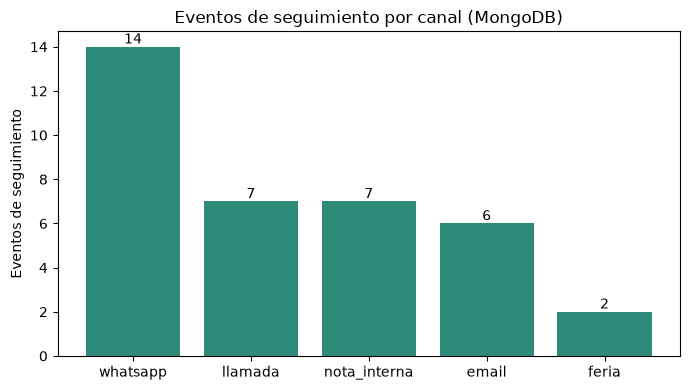

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(a1["canal"], a1["eventos"], color="#2E8B7A")
for x, y in zip(a1["canal"], a1["eventos"]):
    ax.text(x, y, str(y), ha="center", va="bottom")
ax.set_ylabel("Eventos de seguimiento"); ax.set_title("Eventos de seguimiento por canal (MongoDB)")
plt.tight_layout()
(RAIZ / "mongodb" / "figuras").mkdir(exist_ok=True)
fig.savefig(RAIZ / "mongodb" / "figuras" / "eventos_por_canal.png", dpi=200)
plt.show()

## 10. Exportación y validación final

In [11]:
ruta = RAIZ / "mongodb" / "export" / "seguimiento_eventos_export.json"
ruta.parent.mkdir(exist_ok=True)
ruta.write_text(json_util.dumps(list(col.find({}, {"_id": 0}).sort([("solicitud_id", 1), ("ocurrio_en", 1)])), ensure_ascii=False, indent=1), encoding="utf-8")
final = {
    "documentos en la colección": col.count_documents({}),
    "problemas de referencia frente a PostgreSQL": validar(v2) or 0,
    "índices": len(col.index_information()),
    "plan con índice": despues[0],
    "canales en A1": len(a1), "filas en A2": len(a2),
    "oportunidades combinadas PostgreSQL + MongoDB": len(hibrido),
    "exportación": str(ruta.relative_to(RAIZ)),
}
for k, v in final.items():
    print(f"{k:<46} {v}")
assert final["documentos en la colección"] == 36 and final["problemas de referencia frente a PostgreSQL"] == 0

documentos en la colección                     36
problemas de referencia frente a PostgreSQL    0
índices                                        3
plan con índice                                IXSCAN
canales en A1                                  5
filas en A2                                    10
oportunidades combinadas PostgreSQL + MongoDB  25
exportación                                    mongodb\export\seguimiento_eventos_export.json
